# Notebook 07: Results Visualization

## Objective

This notebook presents the experimental findings of the Spotlight framework through visualizations.

The visual analysis focuses on:

1. Recommendation quality across different exploration strategies.
2. Exposure distribution between Emerging and Established creators.
3. Changes in the Emerging creator exposure gap.
4. Creator coverage and recommendation diversity.
5. The trade-off between recommendation relevance and creator fairness.

## Experimental Strategies

- Baseline Recommendation (0% Exploration)
- Ordinary Exploration (30%)
- Fairness-Aware Exploration (30%)

## Dataset

KuaiRec — using 1,411 users and 14,110 recommendations per strategy.

## Expected Outcome

Generate clear, publication-quality visualizations that communicate the effectiveness and limitations of fairness-aware recommendation strategies.

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Visualization environment ready!")

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Visualization environment ready!")

Visualization environment ready!


In [2]:
# Recommendation quality results

quality_results = pd.DataFrame({
    "Strategy": [
        "Baseline (0%)",
        "Ordinary Exploration (30%)",
        "Fairness-Aware (30%)"
    ],
    "HitRate@10": [89.30, 88.94, 88.09],
    "Users with hits": [1260, 1255, 1243],
    "Slot Hit Rate": [22.71, 21.79, 21.35]
})

# Creator exposure results

exposure_results = pd.DataFrame({
    "Strategy": [
        "Baseline (0%)",
        "Baseline (0%)",
        "Ordinary Exploration (30%)",
        "Ordinary Exploration (30%)",
        "Fairness-Aware (30%)",
        "Fairness-Aware (30%)"
    ],
    "Creator Group": [
        "Emerging", "Established",
        "Emerging", "Established",
        "Emerging", "Established"
    ],
    "Exposure (%)": [
        10.08, 89.92,
        10.26, 89.74,
        12.67, 87.33
    ],
    "Unique Creators": [
        240, 829,
        236, 815,
        244, 815
    ],
    "Creator Coverage (%)": [
        47.24, 54.43,
        46.46, 53.51,
        48.03, 53.51
    ]
})

# Emerging creator exposure gap

exposure_gap = pd.DataFrame({
    "Strategy": [
        "Baseline (0%)",
        "Ordinary Exploration (30%)",
        "Fairness-Aware (30%)"
    ],
    "Exposure (%)": [10.08, 10.26, 12.67],
    "Population Share (%)": [25.01, 25.01, 25.01],
    "Exposure Gap (pp)": [-14.93, -14.76, -12.34]
})

print("Recommendation Quality")
display(quality_results)

print("Creator Exposure")
display(exposure_results)

print("Emerging Creator Exposure Gap")
display(exposure_gap)

Recommendation Quality


,Strategy,HitRate@10,Users with hits,Slot Hit Rate
0,Baseline (0%),89.30,1260,22.71
1,Ordinary Exploration (30%),88.94,1255,21.79
2,Fairness-Aware (30%),88.09,1243,21.35


Creator Exposure


,Strategy,Creator Group,Exposure (%),Unique Creators,Creator Coverage (%)
0,Baseline (0%),Emerging,10.08,240,47.24
1,Baseline (0%),Established,89.92,829,54.43
2,Ordinary Exploration (30%),Emerging,10.26,236,46.46
3,Ordinary Exploration (30%),Established,89.74,815,53.51
4,Fairness-Aware (30%),Emerging,12.67,244,48.03
5,Fairness-Aware (30%),Established,87.33,815,53.51


Emerging Creator Exposure Gap


,Strategy,Exposure (%),Population Share (%),Exposure Gap (pp)
0,Baseline (0%),10.08,25.01,-14.93
1,Ordinary Exploration (30%),10.26,25.01,-14.76
2,Fairness-Aware (30%),12.67,25.01,-12.34


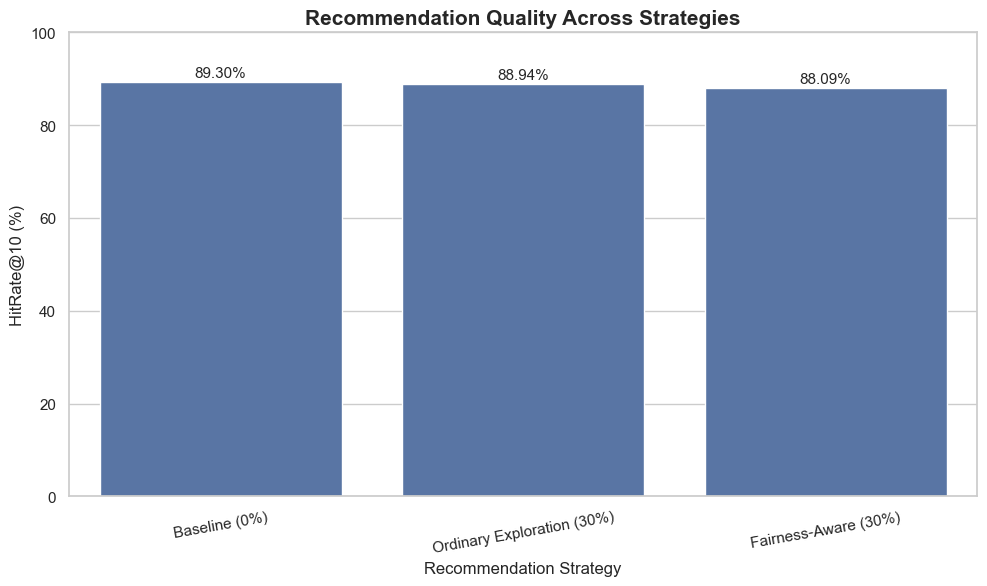

In [3]:
# Visualization 1: Recommendation Quality Comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=quality_results,
    x="Strategy",
    y="HitRate@10"
)

plt.title(
    "Recommendation Quality Across Strategies",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recommendation Strategy")
plt.ylabel("HitRate@10 (%)")

plt.ylim(0, 100)
plt.xticks(rotation=10)

for i, value in enumerate(quality_results["HitRate@10"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

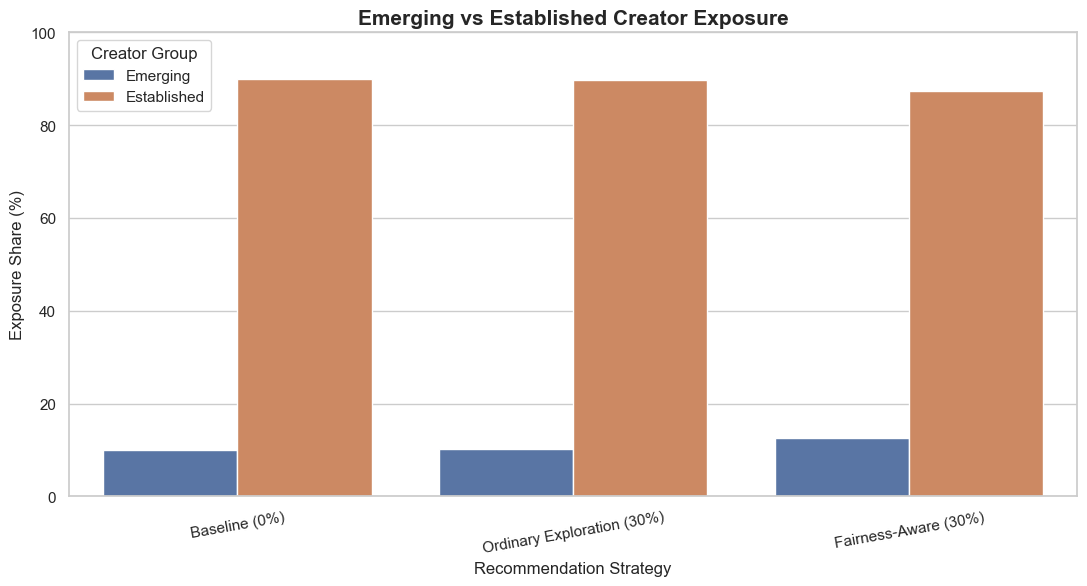

In [4]:
# Visualization 2: Creator Exposure Comparison

plt.figure(figsize=(11, 6))

sns.barplot(
    data=exposure_results,
    x="Strategy",
    y="Exposure (%)",
    hue="Creator Group"
)

plt.title(
    "Emerging vs Established Creator Exposure",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recommendation Strategy")
plt.ylabel("Exposure Share (%)")

plt.ylim(0, 100)
plt.xticks(rotation=10)
plt.legend(title="Creator Group")

plt.tight_layout()
plt.show()

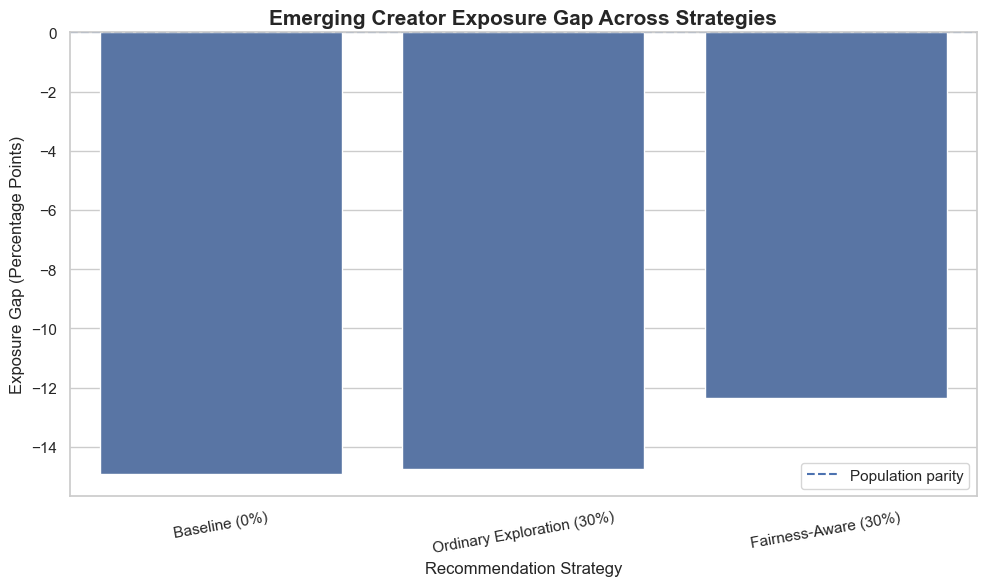

In [5]:
# Visualization 3: Emerging Creator Exposure Gap

plt.figure(figsize=(10, 6))

sns.barplot(
    data=exposure_gap,
    x="Strategy",
    y="Exposure Gap (pp)"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1.5,
    label="Population parity"
)

plt.title(
    "Emerging Creator Exposure Gap Across Strategies",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recommendation Strategy")
plt.ylabel("Exposure Gap (Percentage Points)")

plt.xticks(rotation=10)
plt.legend()

plt.tight_layout()
plt.show()

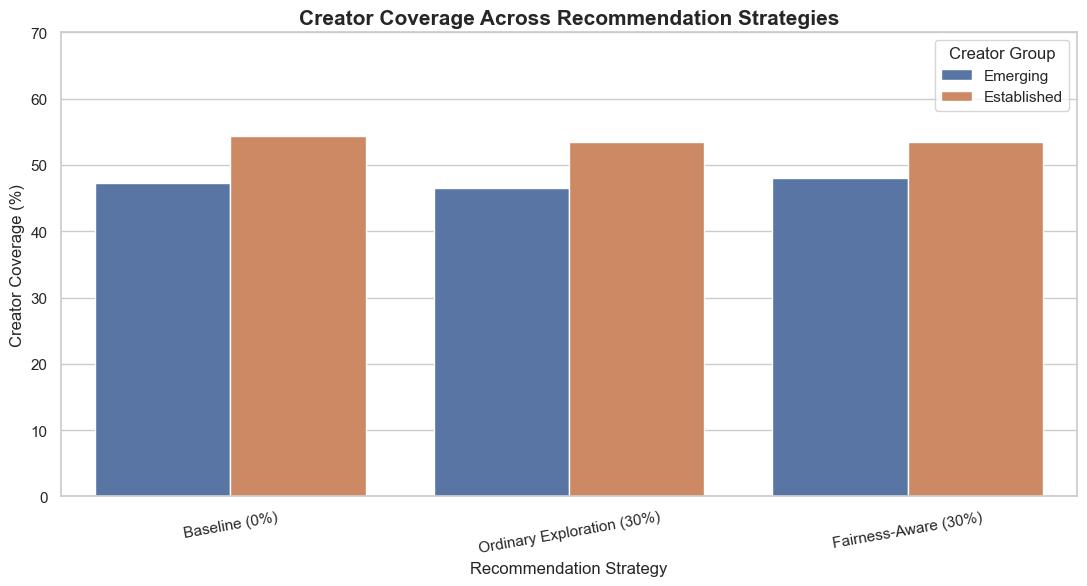

In [6]:
# Visualization 4: Creator Coverage Comparison

plt.figure(figsize=(11, 6))

sns.barplot(
    data=exposure_results,
    x="Strategy",
    y="Creator Coverage (%)",
    hue="Creator Group"
)

plt.title(
    "Creator Coverage Across Recommendation Strategies",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recommendation Strategy")
plt.ylabel("Creator Coverage (%)")

plt.ylim(0, 70)
plt.xticks(rotation=10)
plt.legend(title="Creator Group")

plt.tight_layout()
plt.show()

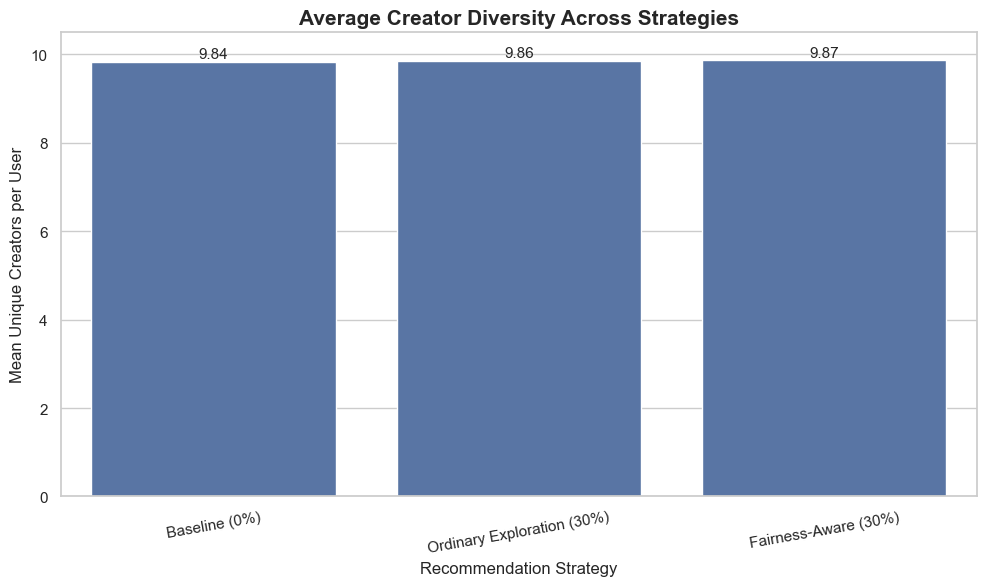

In [9]:
# Visualization 5: Creator Diversity

diversity_results = pd.DataFrame({
    "Strategy": [
        "Baseline (0%)",
        "Ordinary Exploration (30%)",
        "Fairness-Aware (30%)"
    ],
    "Mean Unique Creators": [
        9.84,
        9.86,
        9.87
    ],
    "Median Unique Creators": [
        10,
        10,
        10
    ]
})

plt.figure(figsize=(10, 6))

sns.barplot(
    data=diversity_results,
    x="Strategy",
    y="Mean Unique Creators"
)

plt.title(
    "Average Creator Diversity Across Strategies",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recommendation Strategy")
plt.ylabel("Mean Unique Creators per User")

plt.ylim(0, 10.5)
plt.xticks(rotation=10)

for i, value in enumerate(diversity_results["Mean Unique Creators"]):
    plt.text(i, value + 0.08, f"{value:.2f}", ha="center")

plt.tight_layout()
plt.show()

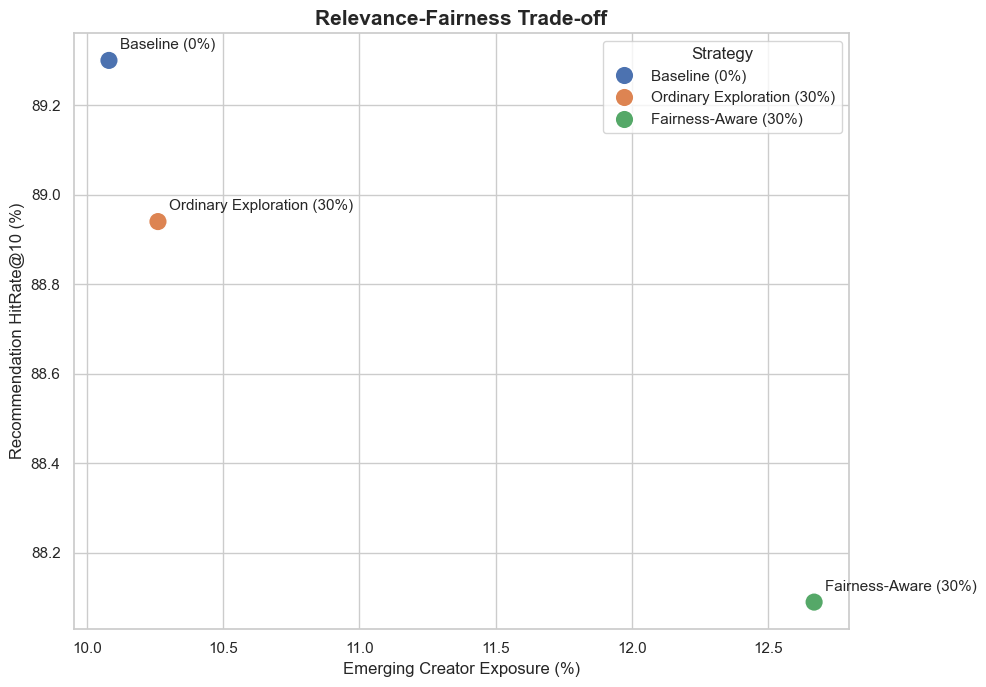

In [8]:
# Visualization 6: Relevance-Fairness Trade-off

tradeoff_results = pd.DataFrame({
    "Strategy": [
        "Baseline (0%)",
        "Ordinary Exploration (30%)",
        "Fairness-Aware (30%)"
    ],
    "Emerging Exposure (%)": [10.08, 10.26, 12.67],
    "HitRate@10 (%)": [89.30, 88.94, 88.09]
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=tradeoff_results,
    x="Emerging Exposure (%)",
    y="HitRate@10 (%)",
    hue="Strategy",
    s=180
)

for _, row in tradeoff_results.iterrows():
    plt.annotate(
        row["Strategy"],
        (
            row["Emerging Exposure (%)"],
            row["HitRate@10 (%)"]
        ),
        xytext=(8, 8),
        textcoords="offset points"
    )

plt.title(
    "Relevance-Fairness Trade-off",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Emerging Creator Exposure (%)")
plt.ylabel("Recommendation HitRate@10 (%)")

plt.tight_layout()
plt.show()

# Final Summary and Research Insights

## 1. Visualizations Created

This notebook presents six visualizations:

1. Recommendation Quality Across Strategies
2. Emerging vs Established Creator Exposure
3. Emerging Creator Exposure Gap
4. Creator Coverage Across Strategies
5. Average Creator Diversity
6. Relevance–Fairness Trade-off

## 2. Key Findings

### Recommendation Quality
- Baseline HitRate@10: 89.30%
- Ordinary Exploration: 88.94%
- Fairness-Aware: 88.09%

The fairness-aware strategy retains relatively high recommendation relevance, with a reduction of 1.21 percentage points compared with baseline.

### Emerging Creator Exposure
- Baseline: 10.08%
- Ordinary Exploration: 10.26%
- Fairness-Aware: 12.67%

The fairness-aware strategy increases Emerging creator exposure by 2.59 percentage points compared with baseline.

### Exposure Gap
The Emerging creator exposure gap decreases from -14.93 to -12.34 percentage points.

### Creator Coverage
Emerging creator coverage increases from 47.24% under baseline to 48.03% under fairness-aware exploration.

### Creator Diversity
Mean unique creators per user:
- Baseline: 9.84
- Ordinary Exploration: 9.86
- Fairness-Aware: 9.87

### Relevance–Fairness Trade-off
The fairness-aware strategy improves Emerging creator exposure while producing a modest reduction in recommendation relevance.

## 3. Overall Research Insight

The visual analysis suggests that ordinary exploration alone is insufficient to substantially improve Emerging creator exposure.

Incorporating a fairness boost into interest-constrained exploration produces a measurable improvement in creator exposure while maintaining relatively high recommendation relevance.

However, the remaining exposure gap indicates that further improvements are needed.

## 4. Conclusion

The Spotlight framework demonstrates the potential of combining user-interest modelling with fairness-aware exploration to improve opportunities for Emerging creators in recommendation systems.

These findings provide the basis for the final research analysis and conclusions in Notebook 08.